# Logprob Metric Distributions

Visualize scalar logprob metrics and token similarity features. Notebook cells set experiment parameters and call version-controlled helpers from `logprob_metrics_distributions_utils.py`.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import pandas as pd
import seaborn as sns

from logprob_metrics_distributions_utils import (
    DEFAULT_METRICS,
    available_metric_columns,
    filter_metrics,
    load_metrics,
    load_token_similarity_stats,
    metric_summary,
    plot_aggregate_similarity_scatter,
    plot_experiment_metric_row,
    plot_global_similarity_scatter,
    plot_metric_distributions,
    plot_similarity_scatter_pair,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

DATA_ROOT = Path(os.environ.get("TEXT_DETECTION_DATA", "D:/Projects/master_diploma/text-detection-data"))
PROCESSED_ROOT = DATA_ROOT / "processed"

## Load Metrics

In [2]:
metrics_df = load_metrics(PROCESSED_ROOT)
metrics_df.head()

,dataset,model,experiment_name,id,split,perplexity,prompt_mu_score,prompt_sigma_score,num_tokens,metrics_version,processed_at,text_len_symbols,text_len_words,text_len_sentences,metrics_path
0,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,749,HG,31.538604,-3.451212,3.498543,701,logprob_metrics_v1,2026-07-17T21:21:02.432814+00:00,3289,584,23,D:\Projects\master_diploma\text-detection-data...
1,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,750,HG,36.091354,-3.586053,3.517463,568,logprob_metrics_v1,2026-07-17T21:21:02.432814+00:00,2738,462,27,D:\Projects\master_diploma\text-detection-data...
2,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,751,HG,34.543532,-3.542220,3.383816,881,logprob_metrics_v1,2026-07-17T21:21:02.440623+00:00,4428,744,48,D:\Projects\master_diploma\text-detection-data...
3,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,752,HG,33.971137,-3.525511,3.441276,832,logprob_metrics_v1,2026-07-17T21:21:02.440623+00:00,4013,686,43,D:\Projects\master_diploma\text-detection-data...
4,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,753,HG,42.235479,-3.743261,3.566881,1064,logprob_metrics_v1,2026-07-17T21:21:02.440623+00:00,4698,871,49,D:\Projects\master_diploma\text-detection-data...


In [3]:
metric_summary(metrics_df)

,dataset,model,split,rows
0,kaggle_train,gemma_3_1b_it,HG,540
1,kaggle_train,gemma_3_1b_it,MG,540
2,kaggle_train,opt_350m,HG,810
3,kaggle_train,opt_350m,MG,810
4,kaggle_train,phi_4_mini_reasoning,HG,181
5,kaggle_train,phi_4_mini_reasoning,MG,121
6,kaggle_train,smollm2_360m,HG,1240
7,kaggle_train,smollm2_360m,MG,1240
8,outfox_chatgpt_all,opt_350m,HG,300
9,outfox_chatgpt_all,opt_350m,MG,300


## Configure Filters

In [4]:
selected_datasets = None
selected_models = None
selected_metrics = [metric for metric in DEFAULT_METRICS if metric in available_metric_columns(metrics_df)]

plot_df = filter_metrics(metrics_df, selected_datasets, selected_models)

print(f"Rows selected: {len(plot_df):,}")
print(f"Datasets: {sorted(plot_df['dataset'].unique())}")
print(f"Models: {sorted(plot_df['model'].unique())}")
print(f"Metrics: {selected_metrics}")

Rows selected: 8,102
Datasets: ['kaggle_train', 'outfox_chatgpt_all', 'outfox_chatgpt_train']
Models: ['gemma_3_1b_it', 'opt_350m', 'phi_4_mini_reasoning', 'smollm2_360m']
Metrics: ['prompt_mu_score', 'prompt_sigma_score', 'perplexity', 'num_tokens', 'text_len_words']


## Metric Distributions

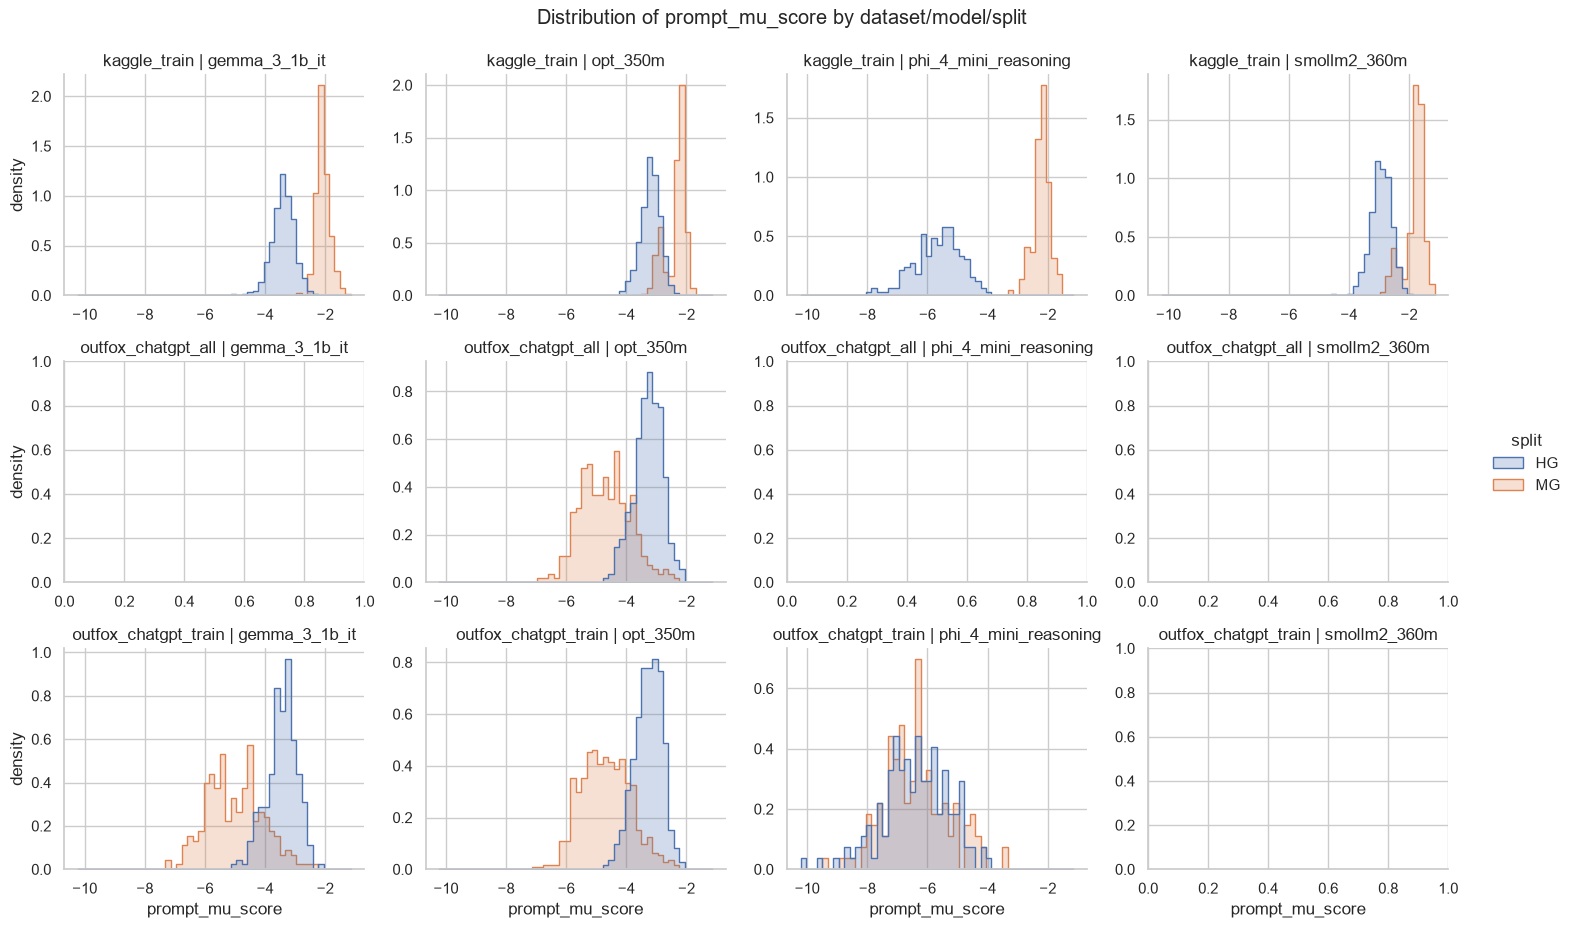

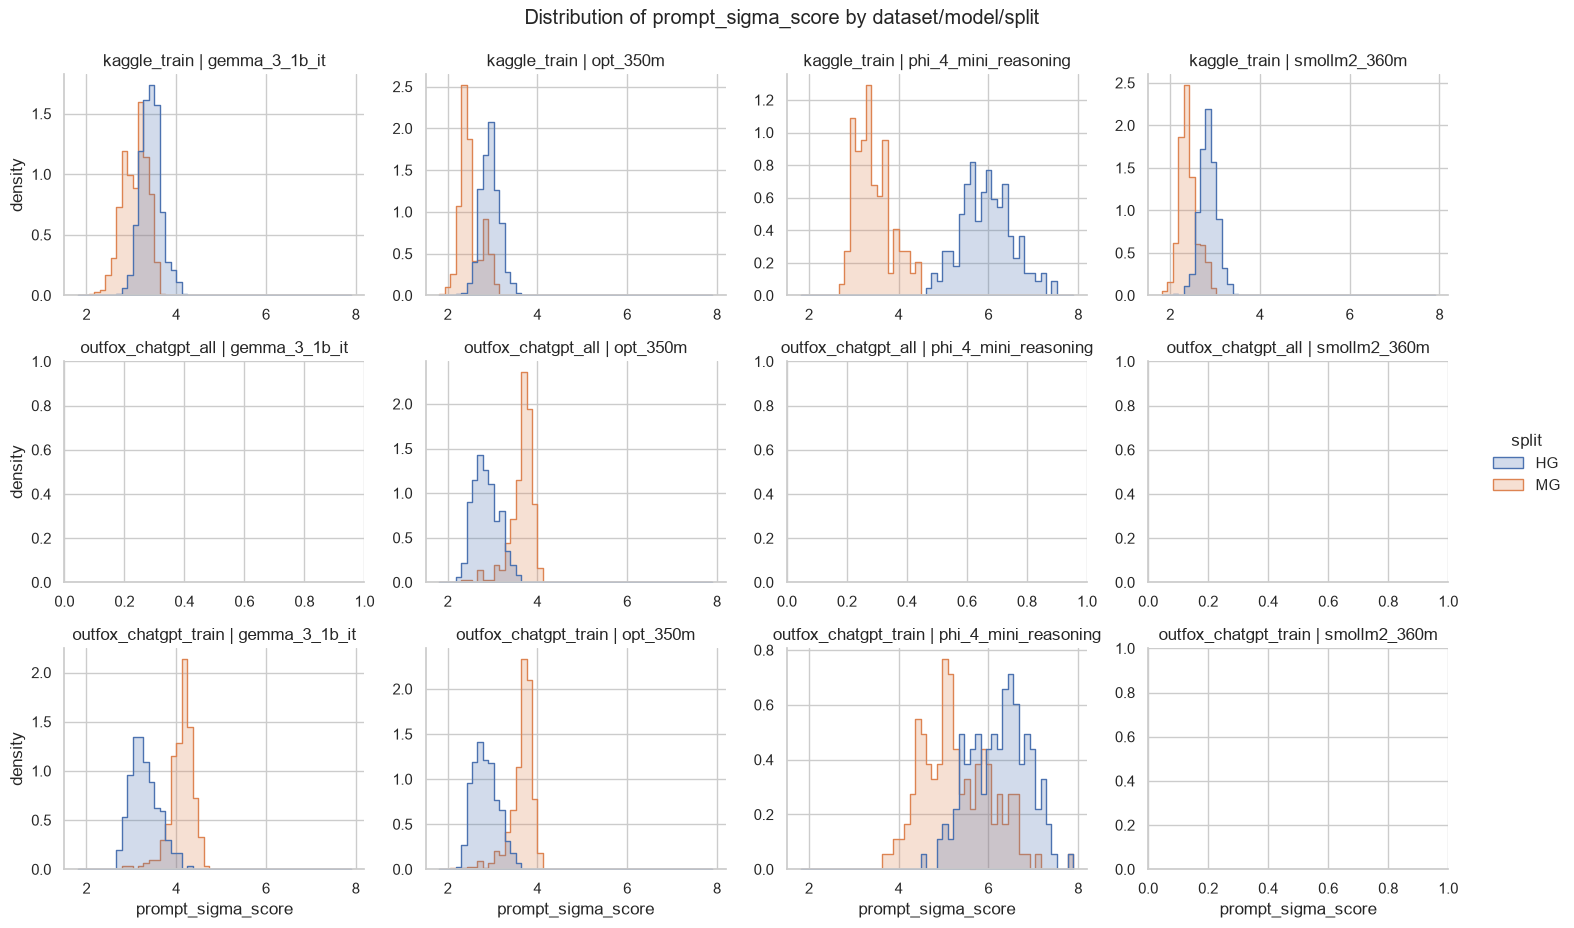

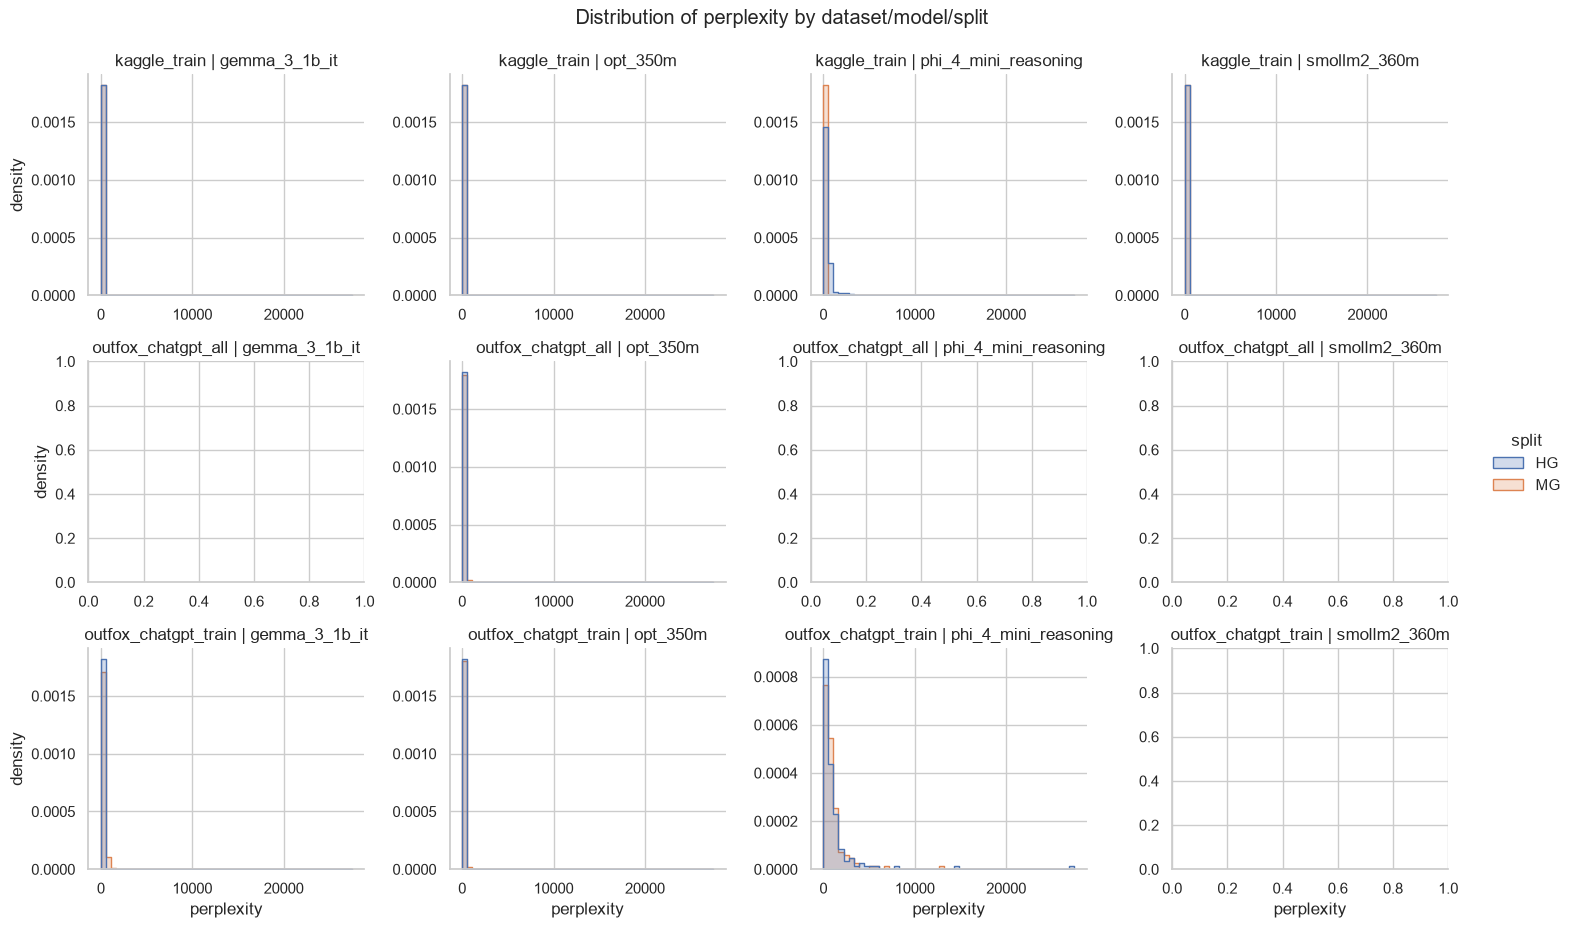

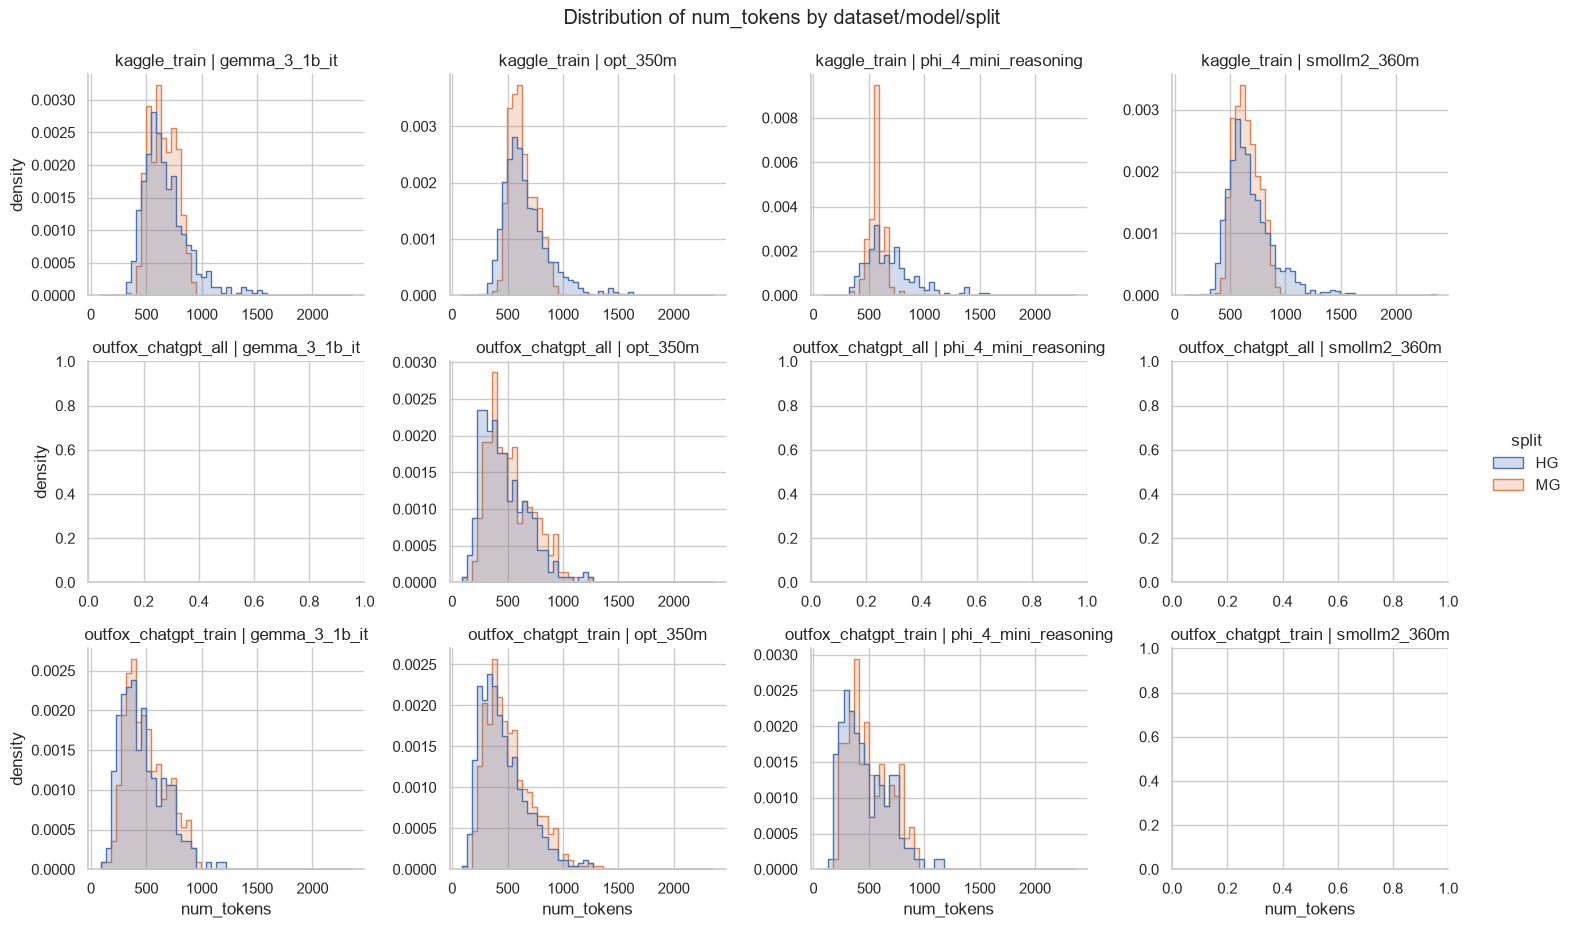

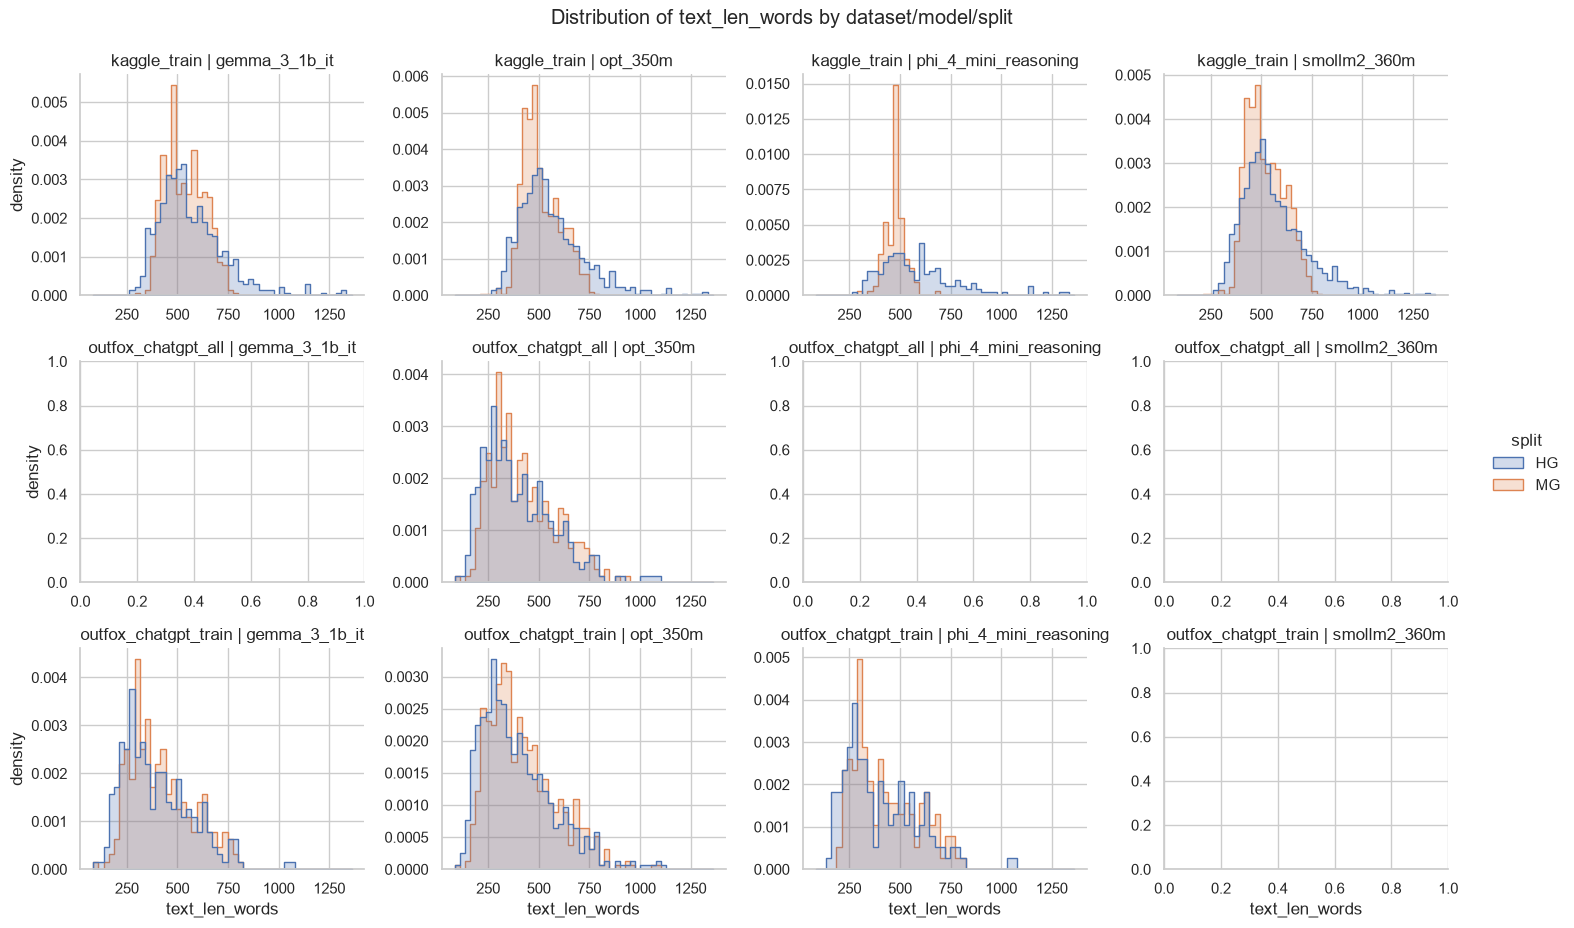

In [5]:
for metric in selected_metrics:
    plot_metric_distributions(plot_df, metric)

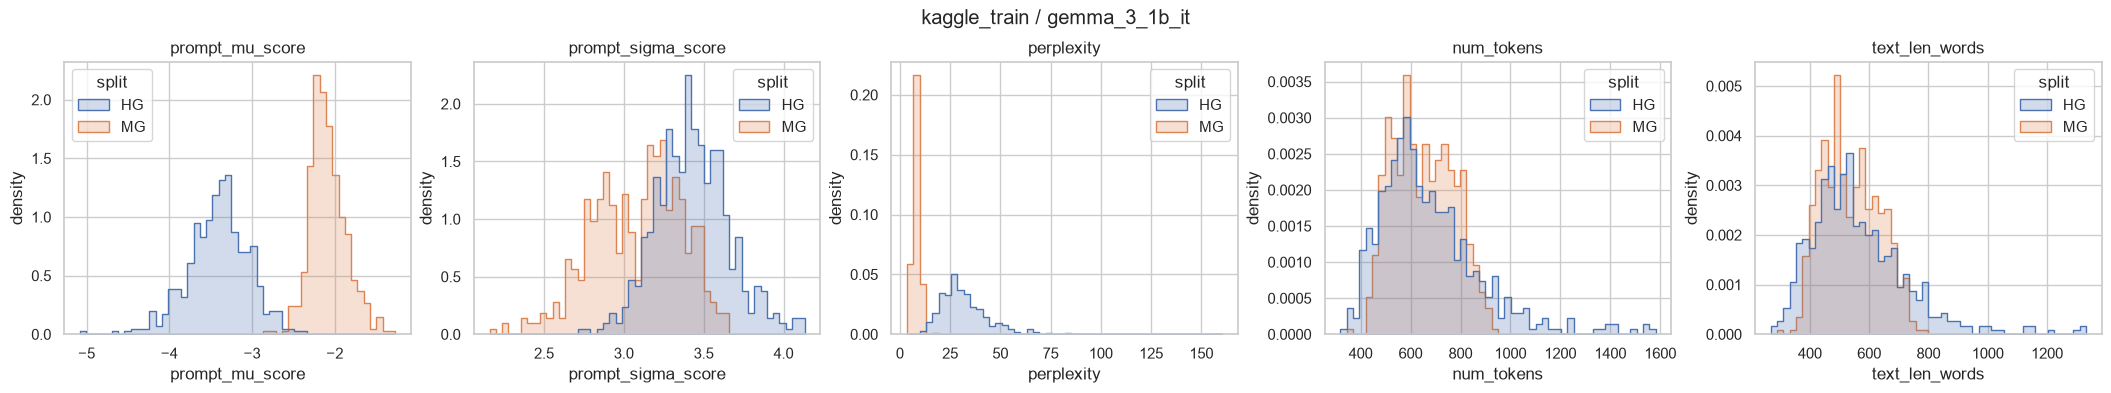

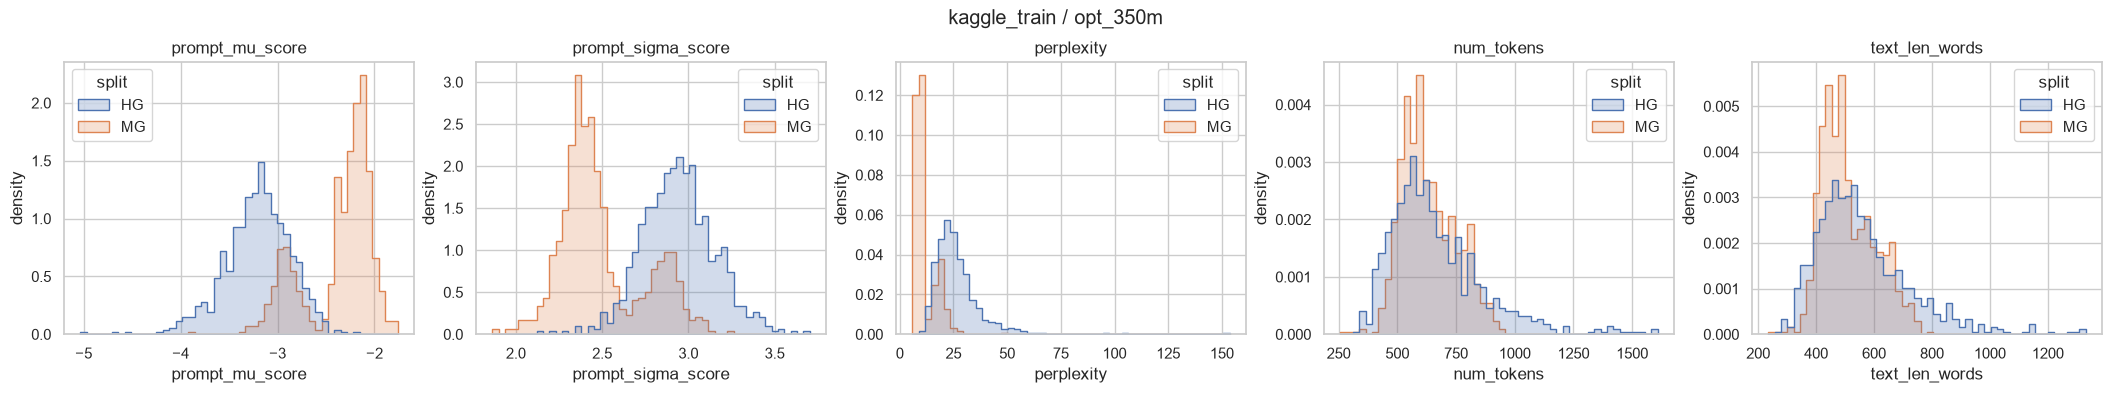

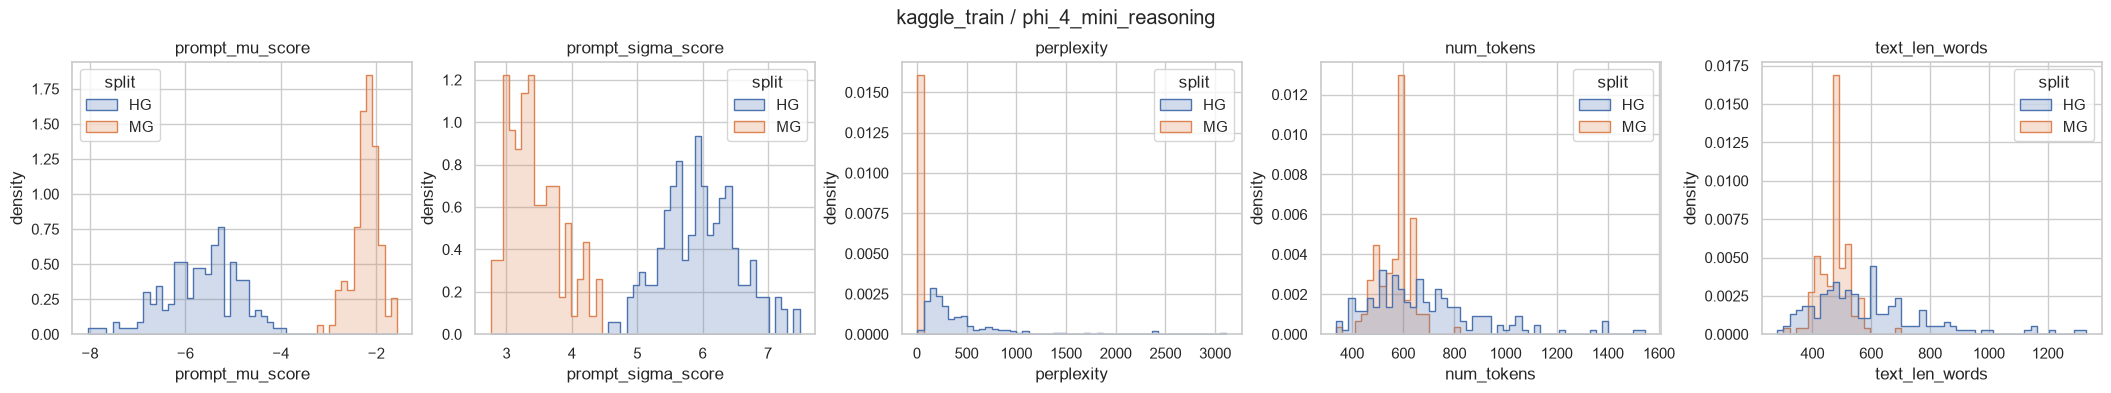

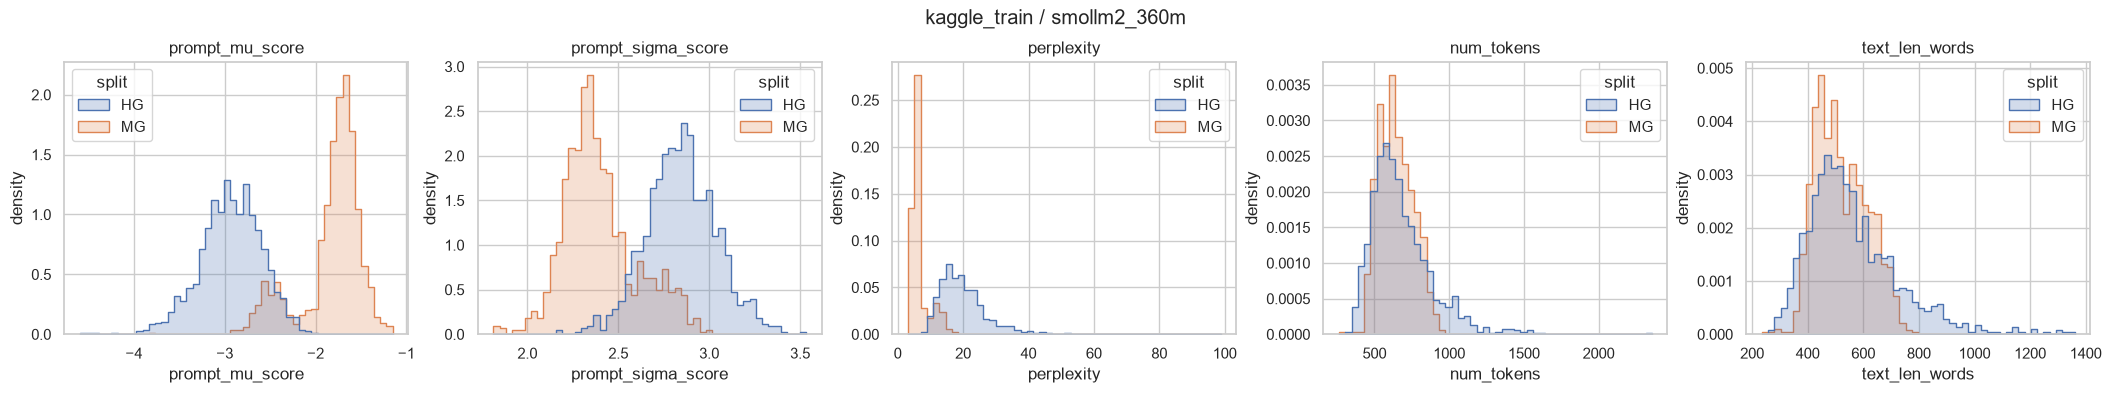

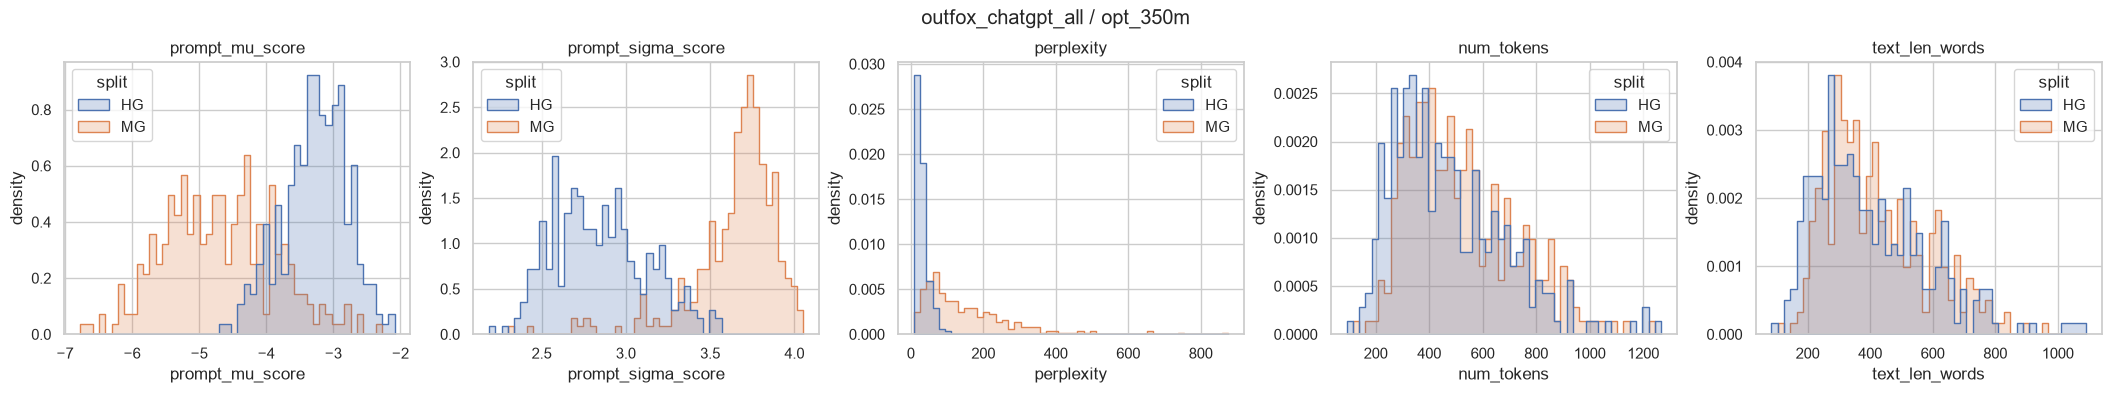

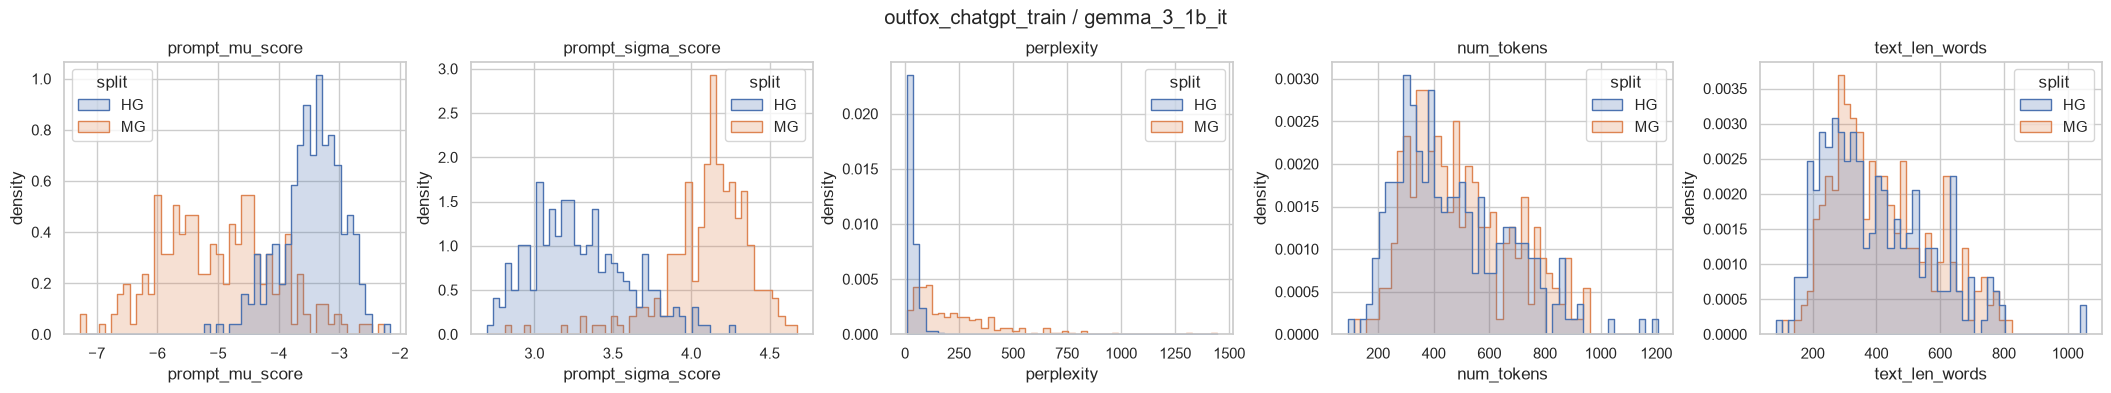

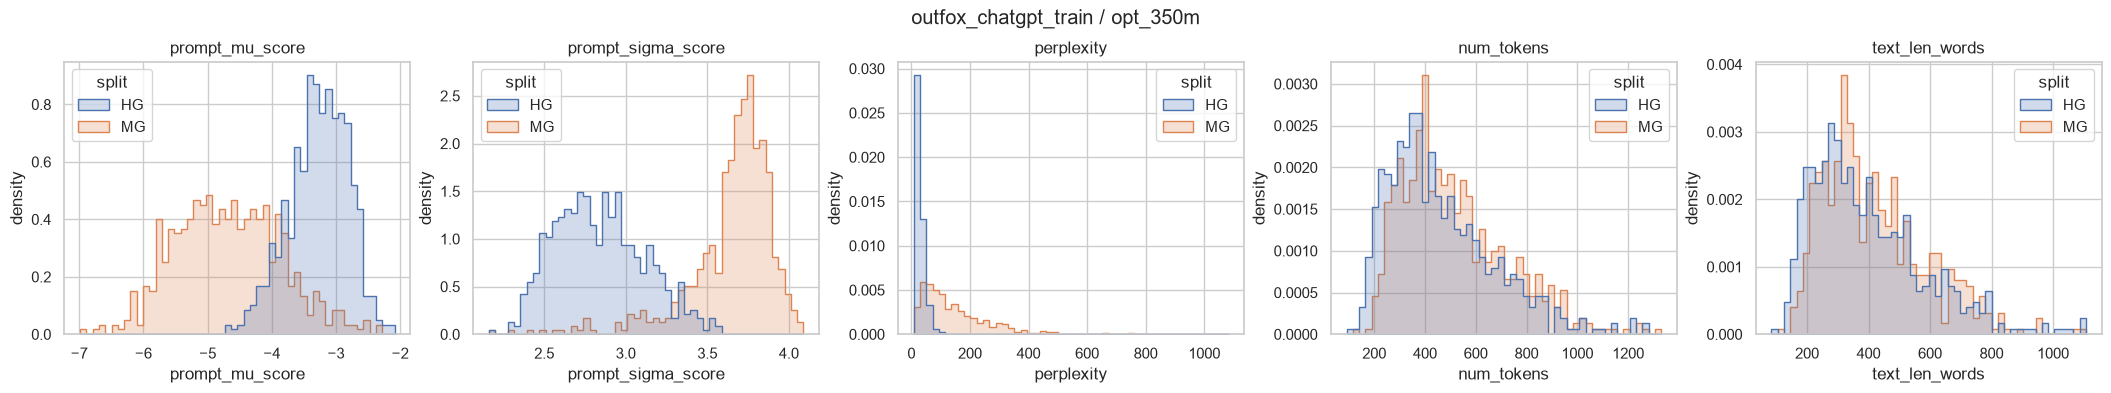

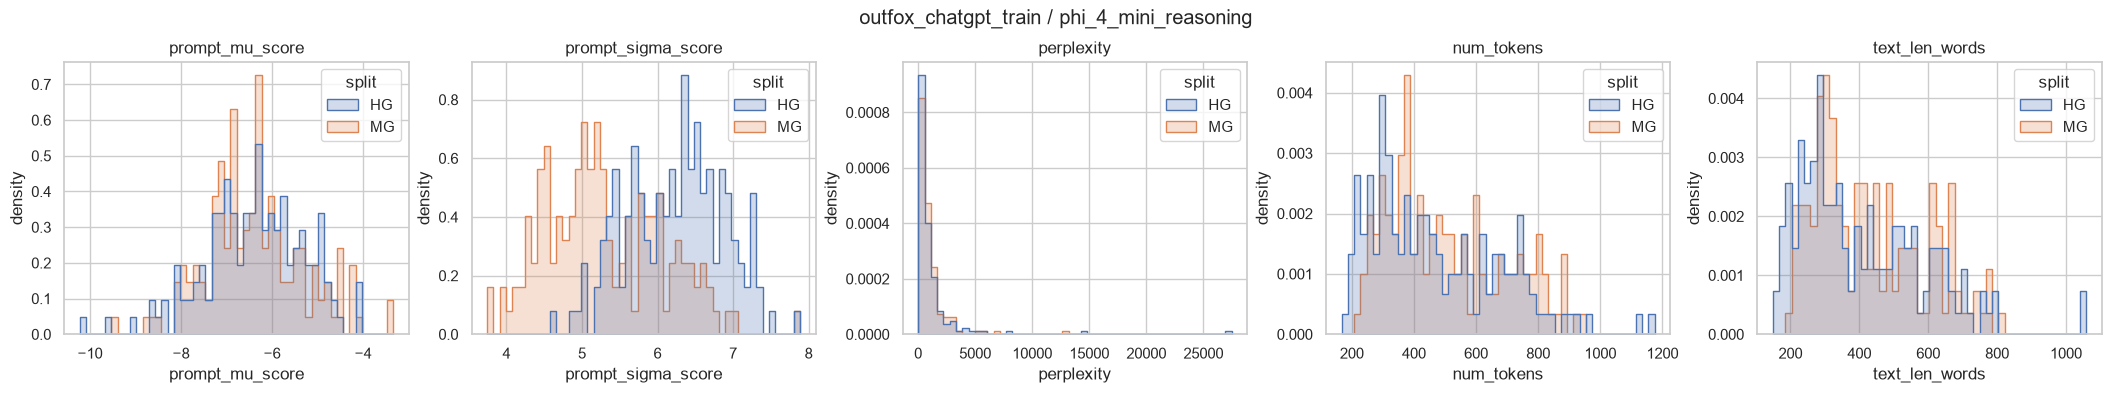

In [6]:
for dataset, model in plot_df[["dataset", "model"]].drop_duplicates().itertuples(index=False):
    plot_experiment_metric_row(plot_df, dataset, model, selected_metrics)

## Numeric Summary

In [7]:
plot_df.groupby(["dataset", "model", "split"])[selected_metrics].describe().round(4)

prompt_mu_score          \
                                                          count    mean   
dataset              model                split                           
kaggle_train         gemma_3_1b_it        HG              540.0 -3.4053   
                                          MG              540.0 -2.0865   
                     opt_350m             HG              810.0 -3.2084   
                                          MG              810.0 -2.3720   
                     phi_4_mini_reasoning HG              181.0 -5.6720   
                                          MG              121.0 -2.2200   
                     smollm2_360m         HG             1240.0 -2.9339   
                                          MG             1240.0 -1.8287   
outfox_chatgpt_all   opt_350m             HG              300.0 -3.2749   
                                          MG              300.0 -4.6944   
outfox_chatgpt_train gemma_3_1b_it        HG              250.0 -3.4583   
                                          MG              250.0 -5.0154   
                     opt_350m             HG              610.0 -3.2739   
                                          MG              610.0 -4.6820   
                     phi_4_mini_reasoning HG              150.0 -6.4039   
                                          MG              150.0 -6.3777   

                                                                          \
                                                    std      min     25%   
dataset              model                split                            
kaggle_train         gemma_3_1b_it        HG     0.3640  -5.0772 -3.6320   
                                          MG     0.2159  -2.8360 -2.2306   
                     opt_350m             HG     0.3384  -5.0348 -3.4080   
                                          MG     0.3525  -3.8779 -2.5423   
                     phi_4_mini_reasoning HG     0.7792  -8.0433 -6.2026   
                                          MG     0.2740  -3.1859 -2.3425   
                     smollm2_360m         HG     0.3401  -4.5929 -3.1448   
                                          MG     0.3408  -3.7971 -1.9139   
outfox_chatgpt_all   opt_350m             HG     0.4760  -4.6473 -3.5567   
                                          MG     0.8201  -6.7754 -5.3321   
outfox_chatgpt_train gemma_3_1b_it        HG     0.5027  -5.1409 -3.7461   
                                          MG     0.9286  -7.2759 -5.7231   
                     opt_350m             HG     0.4592  -4.6646 -3.5645   
                                          MG     0.8145  -6.9867 -5.2758   
                     phi_4_mini_reasoning HG     1.1000 -10.2206 -7.0767   
                                          MG     1.0893  -9.4590 -7.1013   

                                                                         \
                                                    50%     75%     max   
dataset              model                split                           
kaggle_train         gemma_3_1b_it        HG    -3.3817 -3.1741 -2.3693   
                                          MG    -2.1158 -1.9619 -1.2686   
                     opt_350m             HG    -3.1875 -2.9795 -2.1977   
                                          MG    -2.2446 -2.1177 -1.7602   
                     phi_4_mini_reasoning HG    -5.5951 -5.1357 -3.9720   
                                          MG    -2.1911 -2.0533 -1.5667   
                     smollm2_360m         HG    -2.9268 -2.6966 -2.0120   
                                          MG    -1.7416 -1.6189 -1.1497   
outfox_chatgpt_all   opt_350m             HG    -3.2352 -2.9327 -2.0855   
                                          MG    -4.7314 -4.1177 -2.3347   
outfox_chatgpt_train gemma_3_1b_it        HG    -3.4077 -3.1251 -2.1563   
                                          MG    -5.0370 -4.4209 -2.2683   
                     opt_350m             HG    -3.2

## Token Similarity Scatter

In [8]:
similarity_stats_df = load_token_similarity_stats(PROCESSED_ROOT)
similarity_stats_df.head()

Similarity files:   0%|          | 0/66 [00:00<?, ?file/s]

HG:   0%|          | 0/100 [00:00<?, ?text/s]

HG:   0%|          | 0/100 [00:00<?, ?text/s]

HG:   0%|          | 0/100 [00:00<?, ?text/s]

HG:   0%|          | 0/100 [00:00<?, ?text/s]

HG:   0%|          | 0/100 [00:00<?, ?text/s]

... (58 outputs left out)

HG:   0%|          | 0/100 [00:00<?, ?text/s]

MG:   0%|          | 0/50 [00:00<?, ?text/s]

MG:   0%|          | 0/100 [00:00<?, ?text/s]

,id,dataset,model,experiment_name,split,selected_similarity_count,selected_similarity_mean,selected_similarity_std,candidate_similarity_token_count,candidate_similarity_mean,candidate_similarity_std
0,749,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,HG,701,0.509685,0.417409,701,0.220547,0.194467
1,750,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,HG,568,0.494400,0.410779,568,0.225061,0.189376
2,751,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,HG,881,0.479283,0.407496,881,0.220396,0.186142
3,752,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,HG,832,0.502352,0.409488,832,0.216019,0.188245
4,753,kaggle_train,gemma_3_1b_it,kaggle_train__gemma_3_1b_it,HG,1064,0.475567,0.408288,1064,0.216260,0.184991


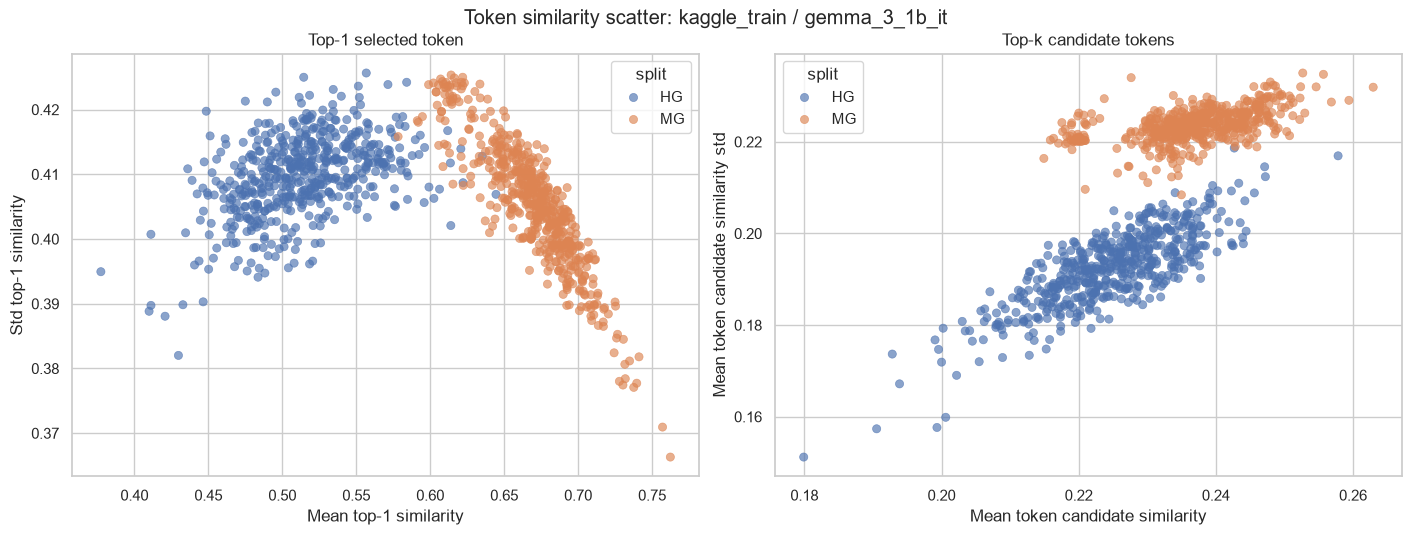

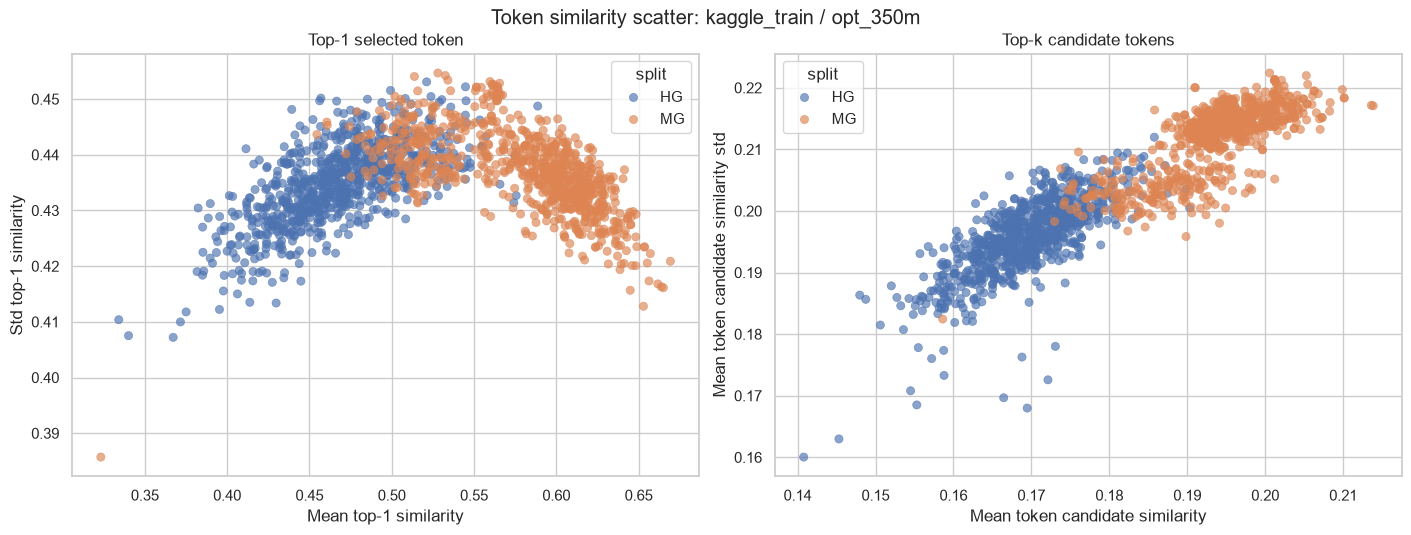

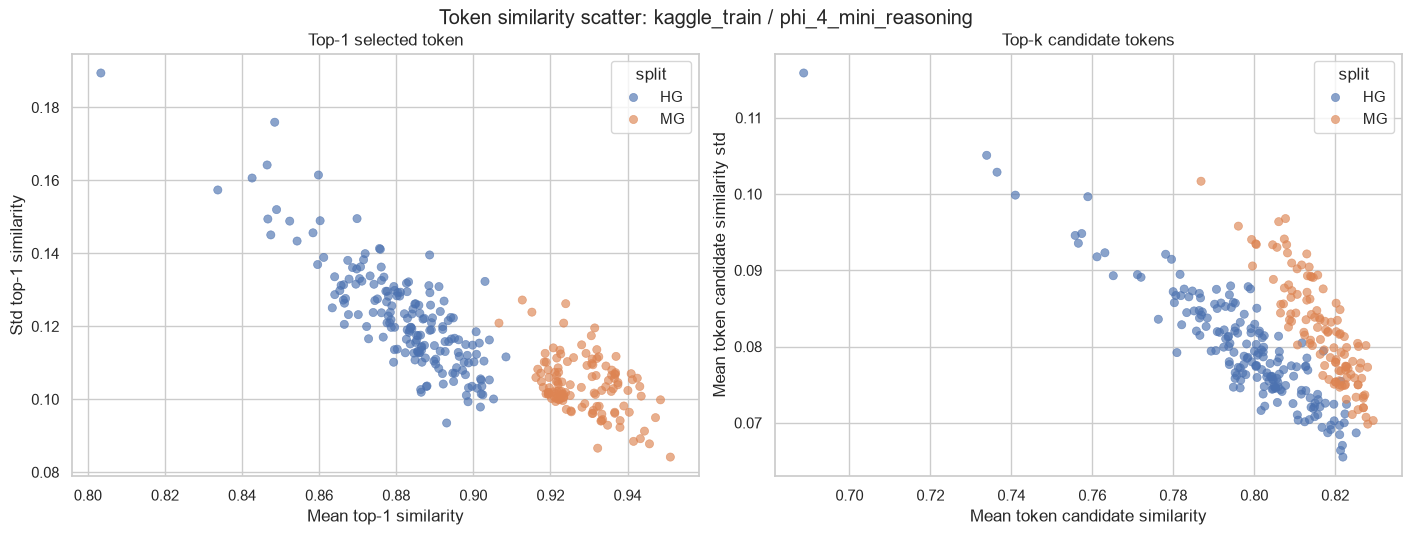

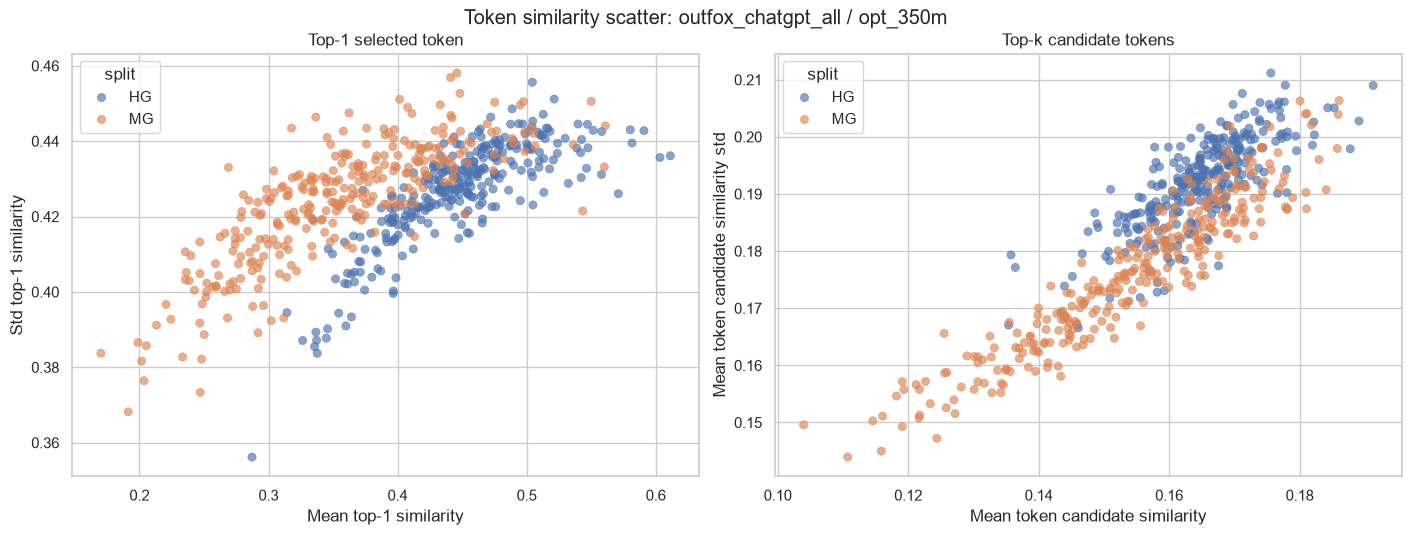

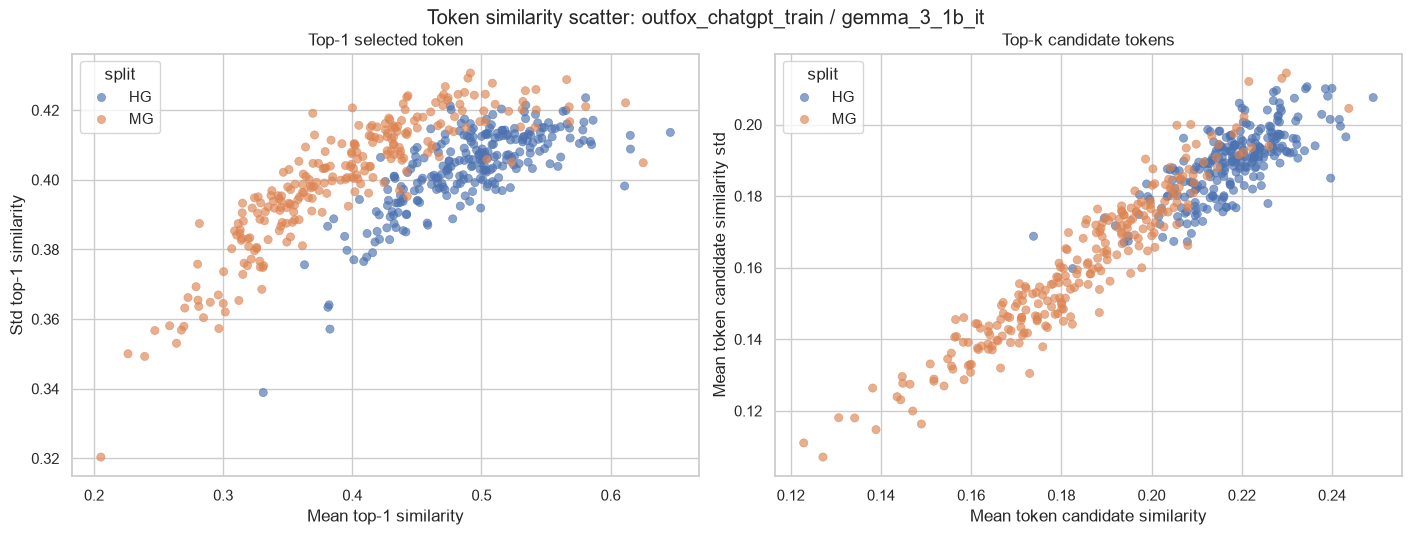

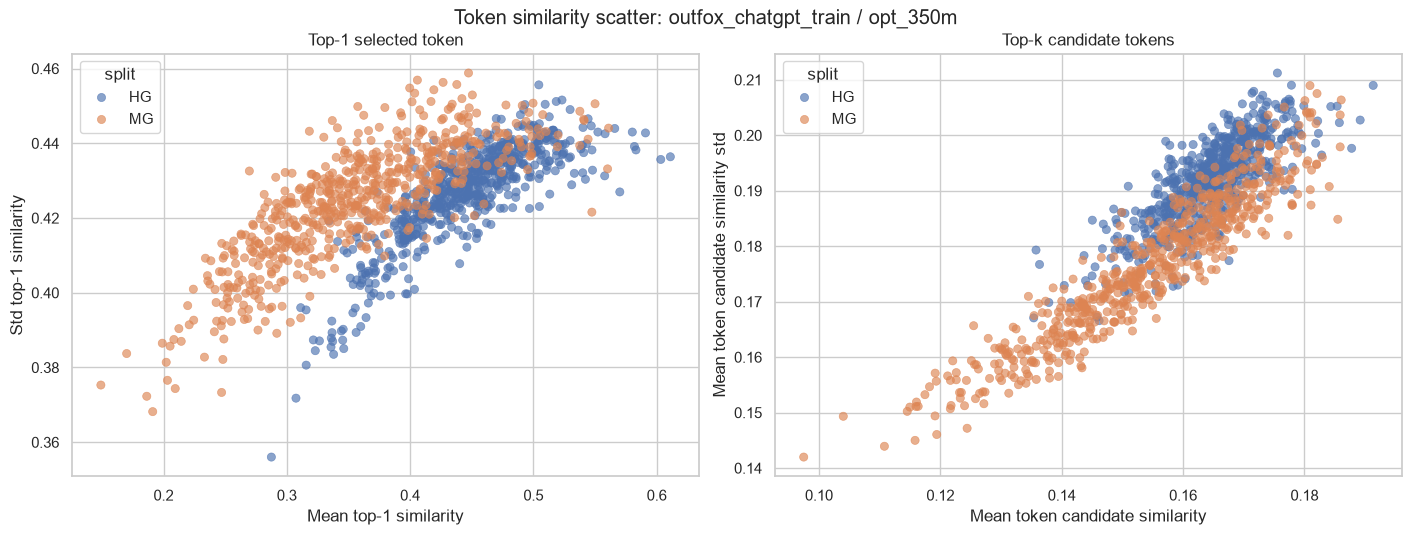

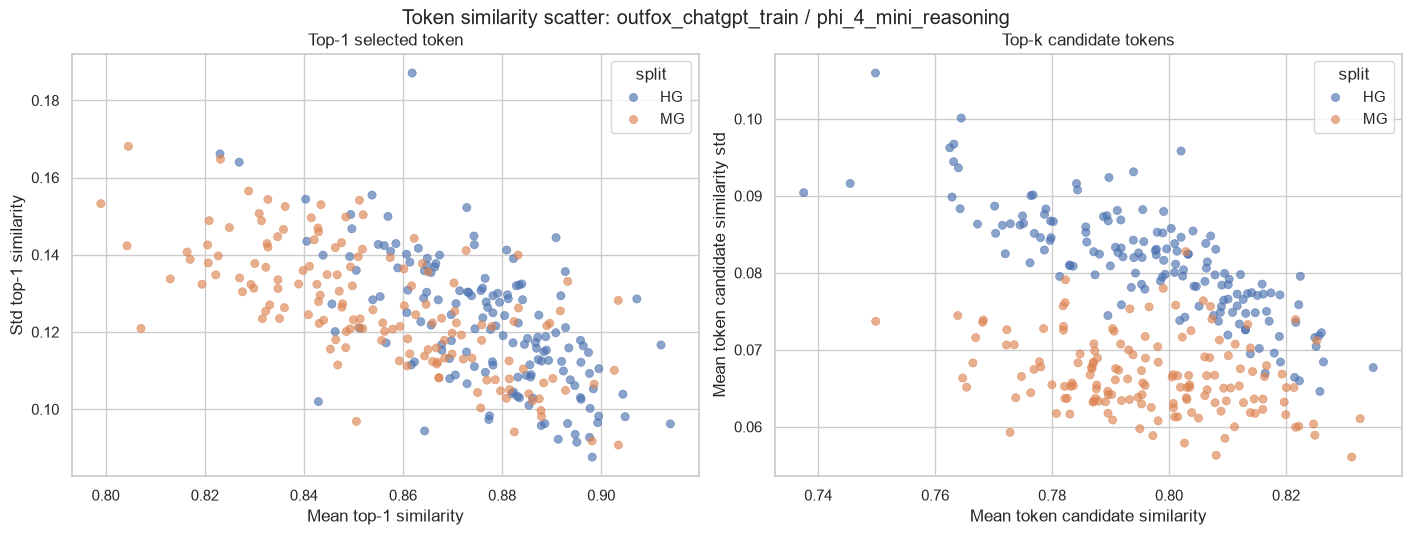

In [9]:
plot_similarity_scatter_pair(similarity_stats_df)

## Aggregate Similarity Scatter

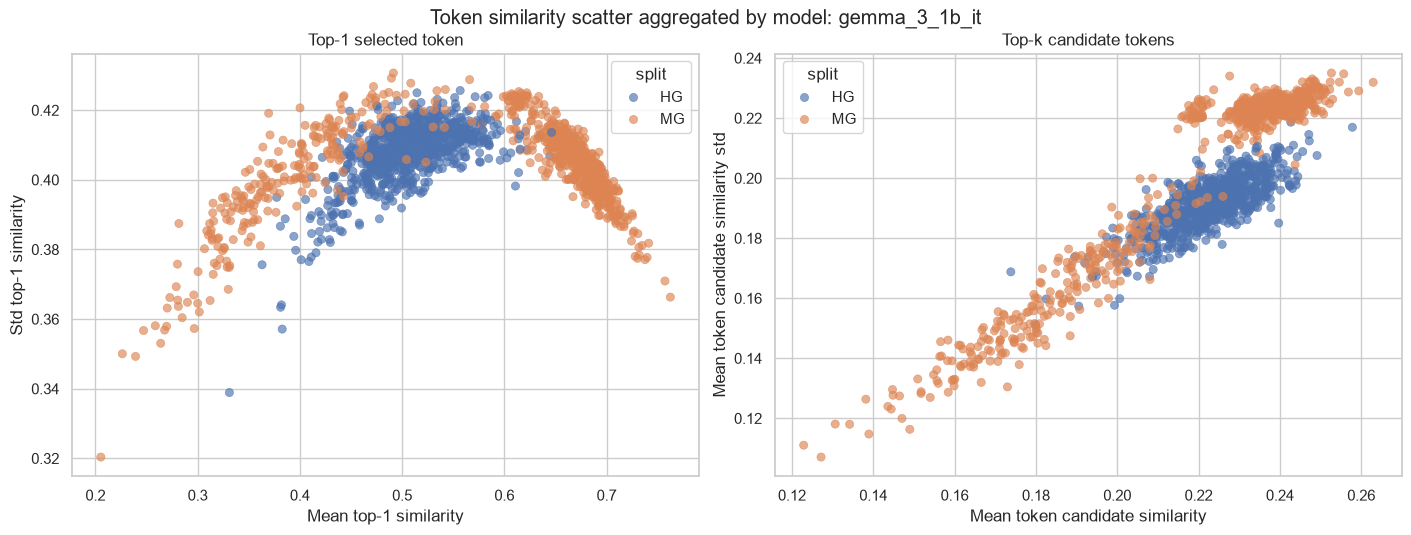

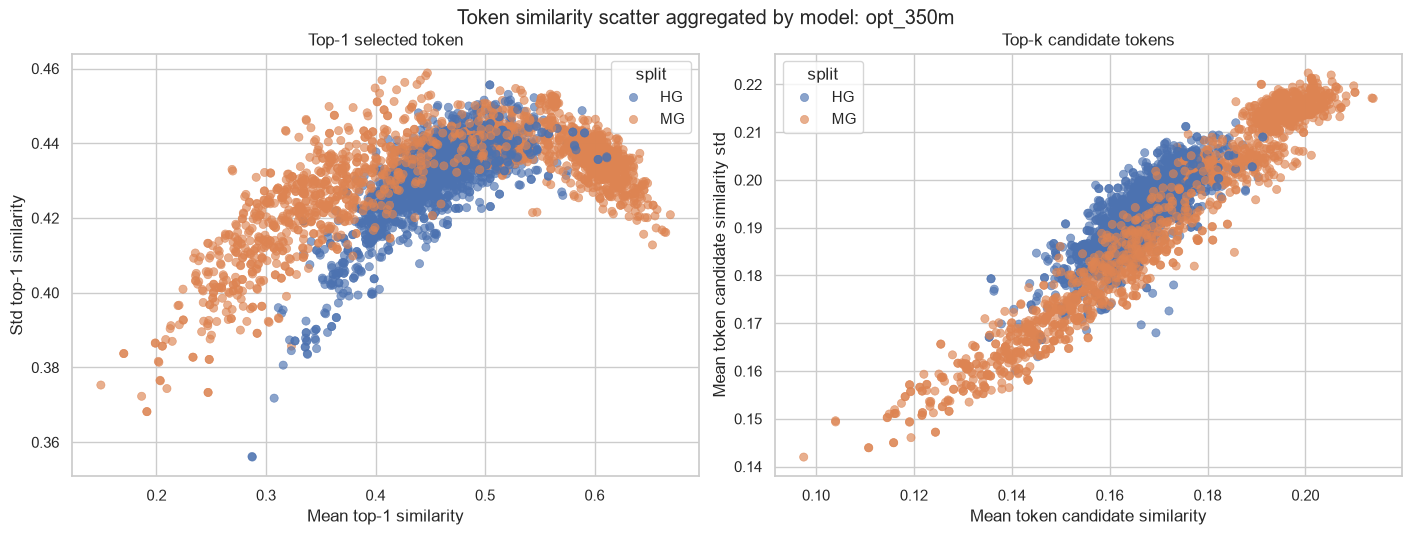

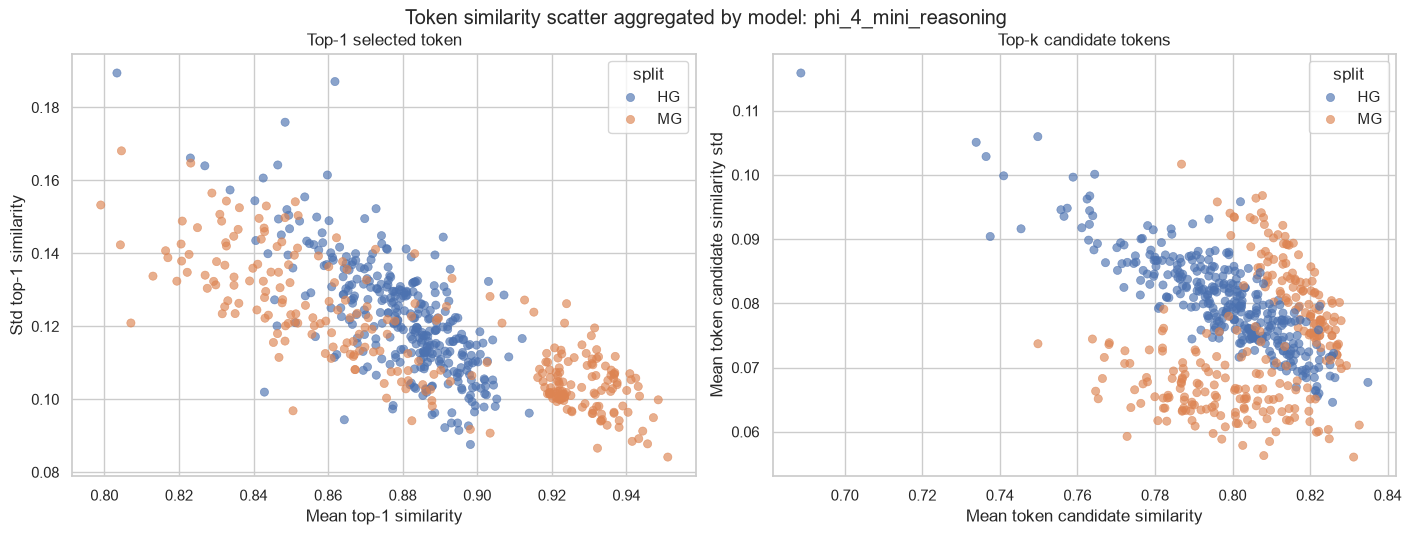

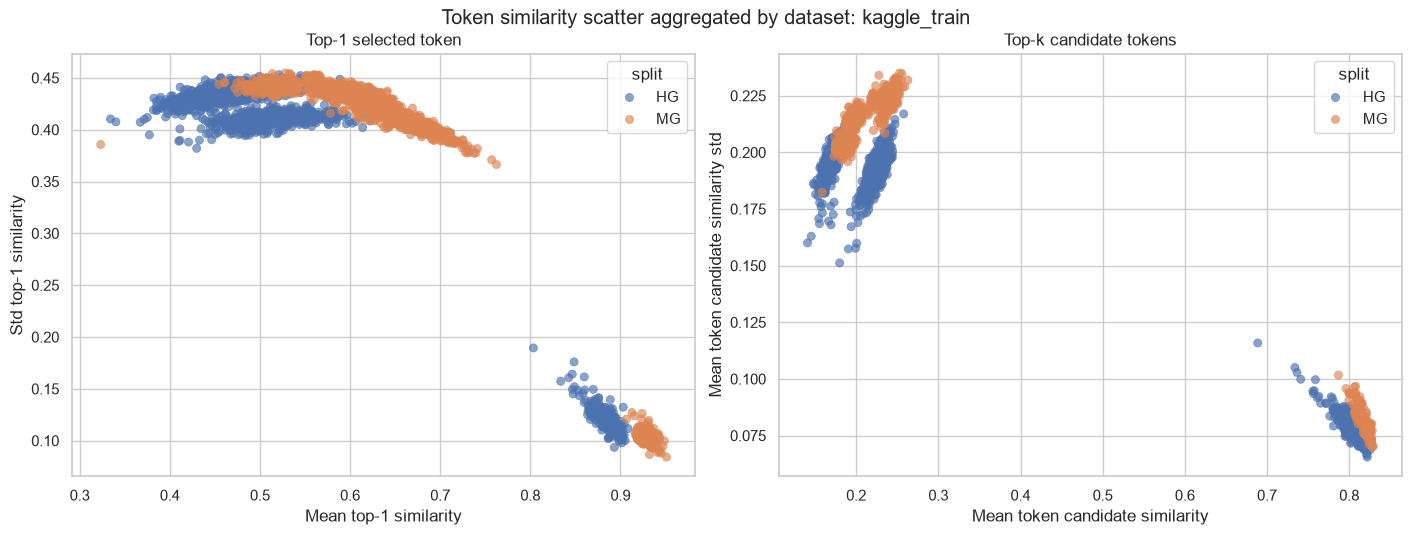

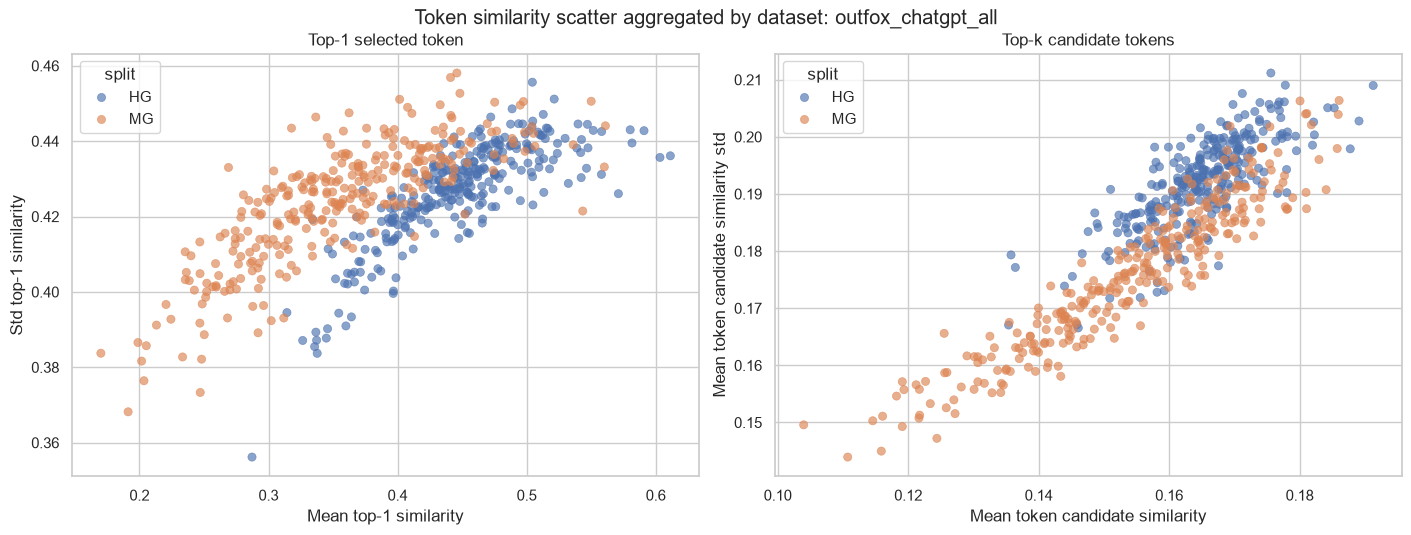

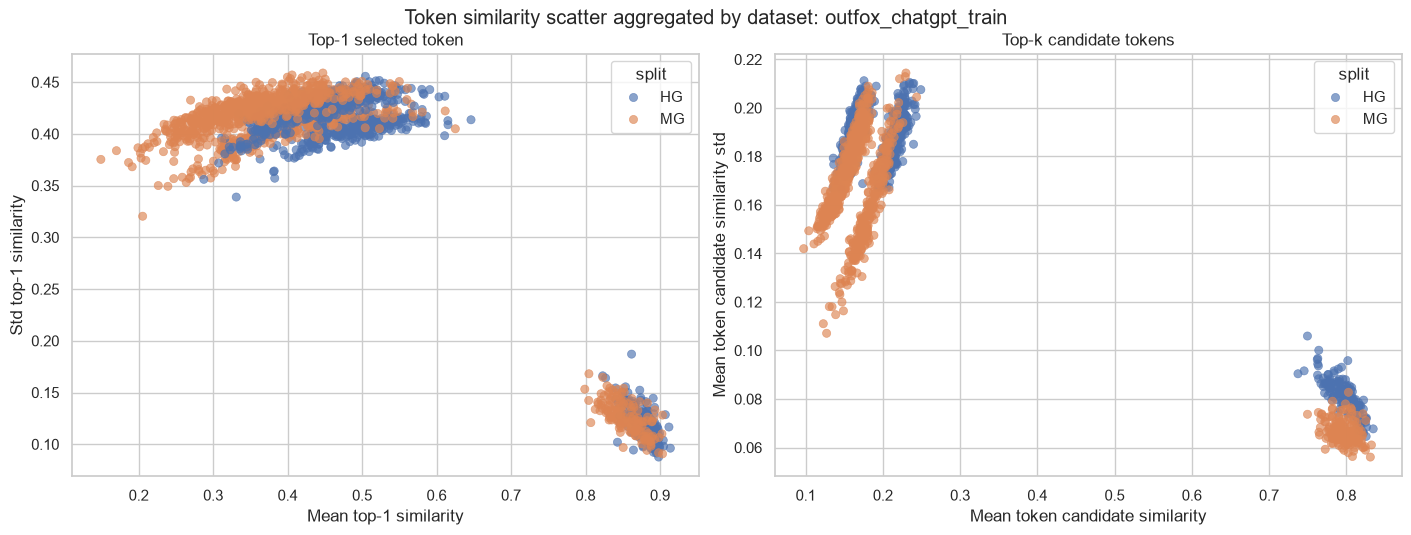

In [10]:
plot_aggregate_similarity_scatter(similarity_stats_df, "model")
plot_aggregate_similarity_scatter(similarity_stats_df, "dataset")

## Global Similarity Scatter

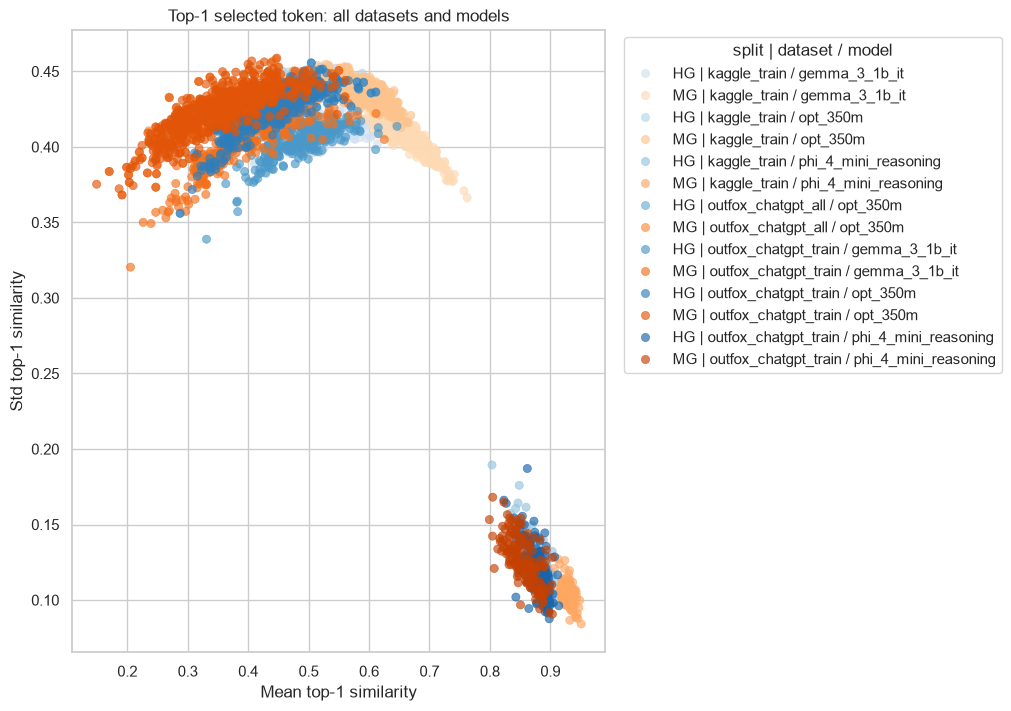

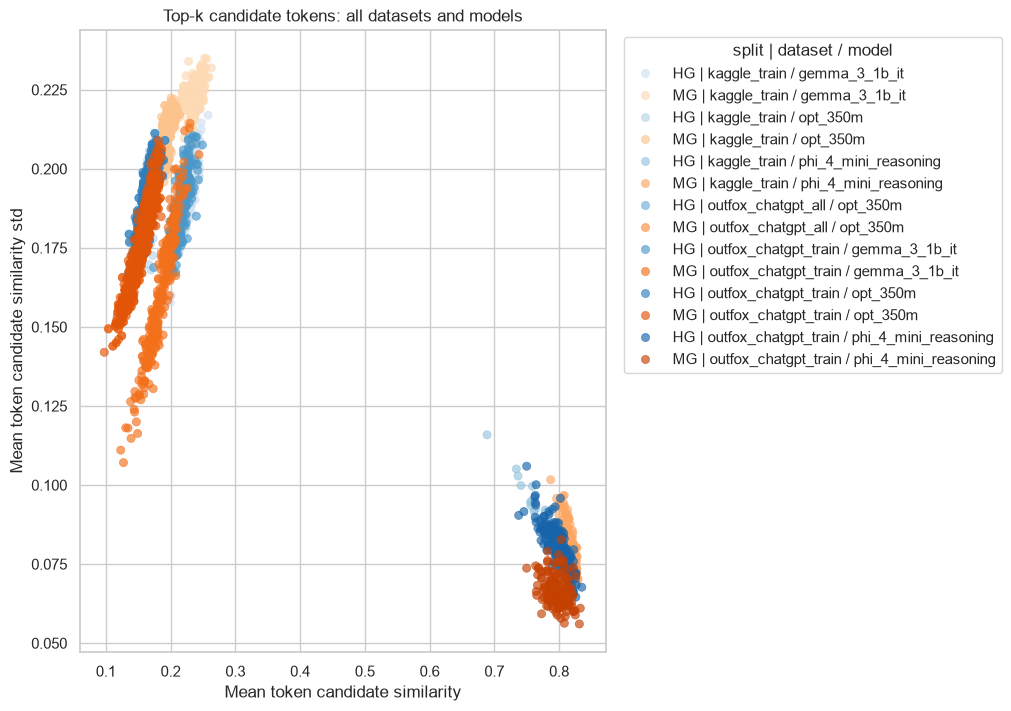

In [11]:
plot_global_similarity_scatter(similarity_stats_df)